In [1]:
#Computer Vision and CNN

In [2]:
import torch
from torch import nn

In [3]:
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

In [4]:
import matplotlib.pyplot as plt

In [5]:
print(torch.__version__)
print(torchvision.__version__)

2.11.0+cu128
0.26.0+cu128


In [6]:
#Getting a Data Set
#We will use FasionMNist

In [7]:
train_data=datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor(),
    target_transform=None
)
test_data=datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor(),
    target_transform=None
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.78MB/s]


In [8]:
len(train_data),len(test_data)


(60000, 10000)

In [9]:
#See the first one
image,label=train_data[0]
image,label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [10]:
class_names=train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [11]:
#To know the labels and their corresponding index we do

In [12]:
class_to_idx=train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [13]:
#To know the labels of train data
train_data.targets

tensor([9, 0, 0,  ..., 3, 0, 5])

In [14]:
#Check shape of out image
image.shape,label

(torch.Size([1, 28, 28]), 9)

In [15]:
print(f"Image Shape : {image.shape}")
print(f"Label : {class_names[label]}")

Image Shape : torch.Size([1, 28, 28])
Label : Ankle boot


In [16]:
#Visualize the data

In [17]:
import matplotlib.pyplot as plt

Label : Ankle boot


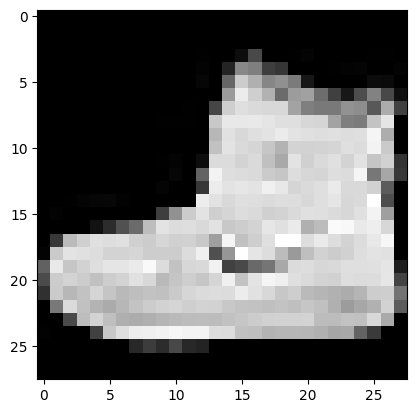

In [18]:
image,label=train_data[0]
print(f"Label : {class_names[label]}")
plt.imshow(image.squeeze(),cmap="gray")
plt.show()

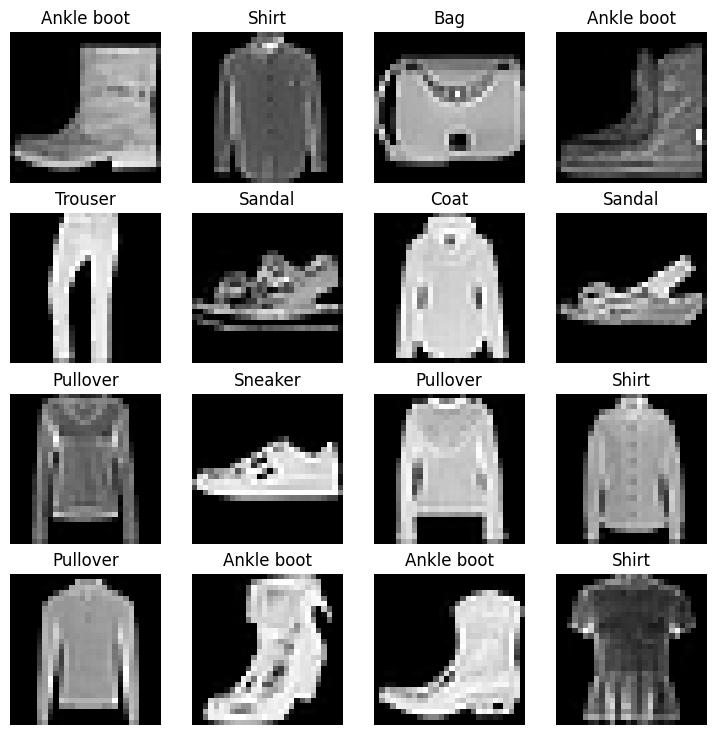

In [19]:
torch.manual_seed(42)
fig=plt.figure(figsize=(9,9))
rows,columns=4,4
for i in range(1,rows*columns+1):
  random_idx=torch.randint(0,len(train_data),size=[1]).item()
  img ,label=train_data[random_idx]
  fig.add_subplot(rows,columns,i)
  plt.imshow(img.squeeze(),cmap='grey')
  plt.title(class_names[label])
  plt.axis(False)


In [20]:
from torch.utils.data import DataLoader
#Setup the batch size hyperparameter
Batch_size=32
train_dataloader=DataLoader(
    dataset=train_data,
    batch_size=Batch_size,
    shuffle=True
)
test_dataloader=DataLoader(
    dataset=test_data,
    batch_size=Batch_size,
    shuffle=False
)

In [21]:
train_dataloader,test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7c4651db3e00>,
 <torch.utils.data.dataloader.DataLoader at 0x7c465111a990>)

In [22]:
print(f"DataLoader : {len(train_dataloader)} batches of {Batch_size} ")
print(f"Dataloader : {len(test_dataloader)} batches of {Batch_size}")

DataLoader : 1875 batches of 32 
Dataloader : 313 batches of 32


In [23]:
train_features_batch,train_labels_batch=next(iter(train_dataloader))
train_features_batch.shape,train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

In [24]:
#Show a sample

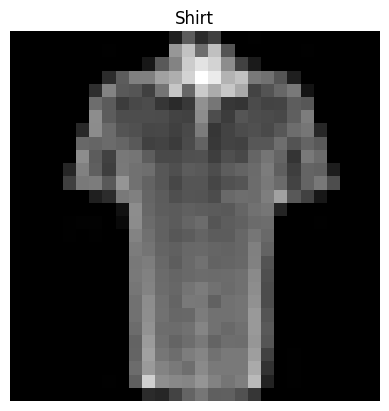

In [25]:
torch.manual_seed(42)
random_idx=torch.randint(0,len(train_features_batch),size=[1]).item()
img,label=train_features_batch[random_idx],train_labels_batch[random_idx]
plt.imshow(img.squeeze(),cmap='grey')
plt.title(class_names[label])
plt.axis(False)
plt.show()

In [26]:
print(f"img size : {img.shape}")
print(f"label : {label}")

img size : torch.Size([1, 28, 28])
label : 6


Build a baseline model:
Baseline model is a simple model you will try to improve upon with subsequent models/experiments

In [27]:
#Create a flatten layer
flatten_model=nn.Flatten()
#Get a single sample
x=train_features_batch[0]
#Flatten the sample
output=flatten_model(x)
#Print out whats happened
print(f"Before flattening {x.shape}")
print(f"After flattening {output.shape}")

Before flattening torch.Size([1, 28, 28])
After flattening torch.Size([1, 784])


In [28]:
from torch import nn
class FashionMNIstModelV0(nn.Module):
  def __init__(self,input_shape:int,hidden_units:int,output_shape:int):
    super().__init__()
    self.linear_stack=nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape,out_features=hidden_units),
        nn.Linear(in_features=hidden_units,out_features=output_shape)
    )
  def forward(self,x:torch.Tensor):
    return self.linear_stack(x)

In [29]:
model_0=FashionMNIstModelV0(input_shape=784,
                            hidden_units=10,
                            output_shape=len(class_names)).to('cpu')

In [30]:
model_0

FashionMNIstModelV0(
  (linear_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [31]:
#Just to check the above model is working
dummy_x=torch.rand([1,1,28,28])
model_0(dummy_x)

tensor([[ 0.4283,  0.1136, -0.3903, -0.0246, -0.0698,  0.2508,  0.4007, -0.4172,
         -0.0264, -0.2463]], grad_fn=<AddmmBackward0>)

In [32]:
model_0.state_dict()

OrderedDict([('linear_stack.1.weight',
              tensor([[ 0.0296, -0.0084,  0.0328,  ...,  0.0093,  0.0135, -0.0188],
                      [-0.0354,  0.0187,  0.0085,  ..., -0.0001,  0.0115, -0.0008],
                      [ 0.0017,  0.0045,  0.0133,  ..., -0.0188,  0.0059,  0.0100],
                      ...,
                      [ 0.0273, -0.0344,  0.0127,  ...,  0.0283, -0.0011, -0.0230],
                      [ 0.0257,  0.0291,  0.0243,  ..., -0.0087,  0.0001,  0.0176],
                      [-0.0147,  0.0053, -0.0194,  ..., -0.0221,  0.0205, -0.0093]])),
             ('linear_stack.1.bias',
              tensor([ 0.0283, -0.0033,  0.0255,  0.0017,  0.0037, -0.0302, -0.0123,  0.0018,
                       0.0163,  0.0069])),
             ('linear_stack.2.weight',
              tensor([[-0.0687,  0.0021,  0.2718,  0.2109,  0.1079, -0.2279, -0.1063,  0.2019,
                        0.2847, -0.1495],
                      [ 0.1344, -0.0740,  0.2006, -0.0475, -0.2514, -0.3130, 

In [33]:
#Setup loss_fn and optimizer

In [34]:
import requests
from pathlib import Path
if Path('helper_functions.py').is_file():
  print('helper_functions.py already exists')
else:
  print('Downloading helper_functions.py')
  request=requests.get('https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py')
  with open('helper_functions.py','wb') as f:
    f.write(request.content)

In [35]:
from helper_functions import accuracy_fn

In [36]:
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.1)

In [37]:
#Creating out model to time our modelling code

In [38]:
from timeit import default_timer as timer

In [39]:
device='cpu'

In [40]:
def print_train_timer(start:float,end:float,device:torch.device=device):
  x=end-start
  print(f"Train time on {device} : {(end-start):.3f} seconds")
  return x

In [41]:
from tqdm.auto import tqdm  #For Progress Bar
#Set the seed and start timer
torch.manual_seed(42)
#Set the no of epochs
epochs=3
train_time_start_on_cpu=timer()
for epoch in tqdm(range(epochs)):
  print(f"Epochs  :    {epoch}")
  #Traing
  train_loss=0
  for batch,(x,y) in enumerate(train_dataloader):
    model_0.train()
    #Forward pass
    y_logits=model_0(x)
    y_pred=torch.softmax(y_logits,dim=1).argmax(dim=1)
    #Calculate the loss
    loss=loss_fn(y_logits,y)
    train_loss+=loss
    #Optimizer zero grad
    optimizer.zero_grad()
    #Loss backward
    loss.backward()
    optimizer.step()

    #Print whats happening
    if batch%400==0:
      print(f"Looked at {batch*len(x)}/{len(train_dataloader.dataset)}")
  train_loss/=len(train_dataloader)
  #Testing Loop
  test_lossx,test_acc=0,0
  model_0.eval()
  with torch.inference_mode():
    for x,y in test_dataloader:
      test_logits=model_0(x)
      test_pred=torch.softmax(test_logits,dim=1).argmax(dim=1)
      test_loss=loss_fn(test_logits,y)
      test_lossx+=test_loss
      test_acc+=accuracy_fn(y_true=y,y_pred=test_pred)

    test_lossx/=len(test_dataloader)
    test_acc/=len(test_dataloader)
  #print out whats happening
  print(f"\nTrain Loss : {train_loss:.5f} | Test Loss : {test_lossx:.5f} | Test Acc : {test_acc:.2f}")
#train time end
train_time_end_on_cpu=timer()
total_train_time_model_0=print_train_timer(start=train_time_start_on_cpu,end=train_time_end_on_cpu,device=str(next(model_0.parameters()).device))
total_train_time_model_0

  0%|          | 0/3 [00:00<?, ?it/s]

Epochs  :    0
Looked at 0/60000
Looked at 12800/60000
Looked at 25600/60000
Looked at 38400/60000
Looked at 51200/60000

Train Loss : 0.59484 | Test Loss : 0.51635 | Test Acc : 81.84
Epochs  :    1
Looked at 0/60000
Looked at 12800/60000
Looked at 25600/60000
Looked at 38400/60000
Looked at 51200/60000

Train Loss : 0.47946 | Test Loss : 0.48138 | Test Acc : 83.18
Epochs  :    2
Looked at 0/60000
Looked at 12800/60000
Looked at 25600/60000
Looked at 38400/60000
Looked at 51200/60000

Train Loss : 0.45703 | Test Loss : 0.47773 | Test Acc : 83.50
Train time on cpu : 28.613 seconds


28.613457581000006

In [42]:
len(train_dataloader.dataset)

60000

In [43]:
#Make predictions and get model 0 predictions
torch.manual_seed(42)
def eval_model(model:torch.nn.Module,data_loader:torch.nn.Module,loss_fn:torch.nn.Module,accuracy_fn):
  loss,acc=0,0
  for x,y in tqdm(data_loader):
    model.eval()
    with torch.inference_mode():
      y_logits=model(x)
      y_pred=torch.softmax(y_logits,dim=1).argmax(dim=1)
      loss+=loss_fn(y_logits,y).item()
      acc+=accuracy_fn(y_true=y,y_pred=y_pred)
  loss/=len(data_loader)
  acc/=len(data_loader)
  return {"model_name":model.__class__.__name__,"model_loss":loss,"model_acc":acc}

In [44]:
model_0_results=eval_model(model=model_0,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn)

  0%|          | 0/313 [00:00<?, ?it/s]

In [45]:
model_0_results

{'model_name': 'FashionMNIstModelV0',
 'model_loss': 0.4777319735517136,
 'model_acc': 83.49640575079871}

In [46]:
#Setup device agnostic code
device='cuda' if torch.cuda.is_available() else 'cpu'
class FashionMNIstModelV1(nn.Module):
  def __init__(self,input_shape:int,hidden_units:int,output_shape:int):
    super().__init__()
    self.linear_stack=nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape,out_features=hidden_units),
        nn.ReLU(),
        nn.Linear(in_features=hidden_units,out_features=output_shape),
        nn.ReLU()
    )
  def forward(self,x:torch.Tensor):
    return self.linear_stack(x)

In [47]:
model_1=FashionMNIstModelV1(input_shape=784,hidden_units=10,output_shape=len(class_names)).to(device)

In [48]:
next(model_1.parameters()).device

device(type='cuda', index=0)

In [49]:
#Setup loss,optimizer and accuracy fn
from helper_functions import accuracy_fn
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(params=model_1.parameters(),lr=0.1)

In [50]:
#Functionizing Training and Testing loop
def train_step(model:torch.nn.Module,data_loader:torch.utils.data.DataLoader,loss_fn:torch.nn.Module,optimizer:torch.optim.Optimizer,accuracy_fn,device:torch.device=device):
  train_loss,acc=0,0
  for batch,(x,y) in enumerate(data_loader):
    x,y=x.to(device),y.to(device)
    model.train()
    y_logits=model(x)
    y_pred=y_logits.softmax(dim=1).argmax(dim=1)
    loss=loss_fn(y_logits,y)
    train_loss+=loss
    ac=accuracy_fn(y_true=y,y_pred=y_pred)
    acc+=ac
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  train_loss/=len(data_loader)
  acc/=len(data_loader)
  print(f"Train Loss : {train_loss:.5f} | Train Acc : {acc:.2f}")
  return {"model_name":model.__class__.__name__,"model_loss":train_loss,"model_acc":acc}

In [51]:
#Testing loop
def test_step(model:torch.nn.Module,data_loader:torch.utils.data.DataLoader,loss_fn:torch.nn.Module,accuracy_fn,device:torch.device=device):
  test_loss,test_acc=0,0
  model.eval()
  with torch.inference_mode():
    for batch,(x,y) in enumerate(data_loader):
      x,y=x.to(device),y.to(device)
      y_logits=model(x)
      y_pred=y_logits.softmax(dim=1).argmax(dim=1)
      loss=loss_fn(y_logits,y)
      test_loss+=loss
      acc=accuracy_fn(y_true=y,y_pred=y_pred)
      test_acc+=acc
    test_loss/=len(data_loader)
    test_acc/=len(data_loader)
    print(f"Test Loss : {test_loss:.5f} | Test Acc : {test_acc:.2f}")
    return {"model_name":model.__class__.__name__,"model_loss":test_loss,"model_acc":test_acc}

In [52]:
#Training and Testing with Traing and Testing functions

In [53]:
torch.manual_seed(42)
#Measure Time
train_time_start_on_gpu=timer()
epochs=3
for epoch in tqdm(range(epochs)):
  print(f"Epochs : {epoch}")
  train_step(model=model_1,data_loader=train_dataloader,loss_fn=loss_fn,optimizer=optimizer,accuracy_fn=accuracy_fn,device=device)
  test_step(model=model_1,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)
train_time_end_on_gpu=timer()
total_train_time_model_1=print_train_timer(start=train_time_start_on_gpu,end=train_time_end_on_gpu)
total_train_time_model_1

  0%|          | 0/3 [00:00<?, ?it/s]

Epochs : 0
Train Loss : 1.11456 | Train Acc : 58.46
Test Loss : 0.96320 | Test Acc : 63.41
Epochs : 1
Train Loss : 0.90905 | Train Acc : 64.87
Test Loss : 0.74544 | Test Acc : 72.61
Epochs : 2
Train Loss : 0.59508 | Train Acc : 78.25
Test Loss : 0.49708 | Test Acc : 82.77
Train time on cpu : 32.796 seconds


32.796220345999984

In [54]:
torch.manual_seed(42)
def eval_model(model:torch.nn.Module,data_loader:torch.nn.Module,loss_fn:torch.nn.Module,accuracy_fn,device=device):
  loss,acc=0,0
  for x,y in tqdm(data_loader):
    x,y=x.to(device),y.to(device)
    model.eval()
    with torch.inference_mode():
      y_logits=model(x)
      y_pred=torch.softmax(y_logits,dim=1).argmax(dim=1)
      loss+=loss_fn(y_logits,y).item()
      acc+=accuracy_fn(y_true=y,y_pred=y_pred)
  loss/=len(data_loader)
  acc/=len(data_loader)

  x={"model_name":model.__class__.__name__,"model_loss":loss,"model_acc":acc}
  return x

In [55]:
model_1_results=eval_model(model=model_1,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

  0%|          | 0/313 [00:00<?, ?it/s]

In [56]:
model_1_results

{'model_name': 'FashionMNIstModelV1',
 'model_loss': 0.497078761553612,
 'model_acc': 82.76757188498402}

In [57]:
#Model 2 Convolutional neural network

In [58]:
class FashionMNISTV2(nn.Module):
  """Model architecture that
  replicates the TinyVGG model from
  CNN Explaier website"""
  def __init__(self,input_shape:int,hidden_units:int,output_shape:int):
    super().__init__()
    self.conv_block_1=nn.Sequential(
        nn.Conv2d(in_channels=input_shape,out_channels=hidden_units,kernel_size=3,padding=1,stride=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units,kernel_size=3,padding=1,stride=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,stride=2)
    )
    self.conv_block_2=nn.Sequential(
        nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units,kernel_size=3,padding=1,stride=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units,kernel_size=3,padding=1,stride=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,stride=2)
    )

    self.classifier=nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*7*7,out_features=output_shape)
    )
  def forward(self,x):
    x=self.conv_block_1(x)
    #print(x.shape)
    x=self.conv_block_2(x)
    #print(x.shape)
    x=self.classifier(x)
    #print(x.shape)
    return x

In [59]:
model_2=FashionMNISTV2(input_shape=1,hidden_units=10,output_shape=len(class_names)).to(device)

In [60]:
#Stepping throuh nn.Conv2d
images=torch.randn(size=(32,3,64,64))
test_image=images[0]
print(test_image.shape)
images.shape

torch.Size([3, 64, 64])


torch.Size([32, 3, 64, 64])

In [61]:
torch.manual_seed(42)
conv_layer=nn.Conv2d(
    in_channels=3,
    out_channels=10,
    kernel_size=3,
    stride=1,
    padding=1
)
conv_output=conv_layer(test_image)
conv_output.shape

torch.Size([10, 64, 64])

In [62]:
maxpool_layer=nn.MaxPool2d(kernel_size=2)
maxpool_output=maxpool_layer(conv_output)
maxpool_output.shape

torch.Size([10, 32, 32])

In [63]:
image

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
          0.2863, 0.0000, 0.0000, 0.0039, 0.0157, 0.0000,

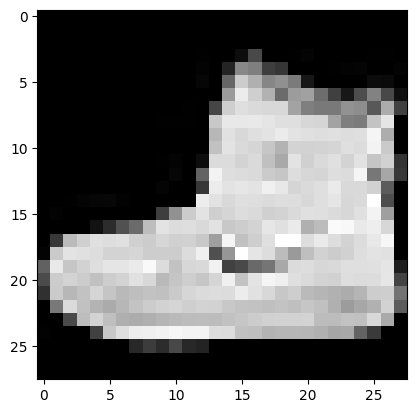

In [64]:
plt.imshow(image.squeeze(),cmap='grey')

In [65]:
image.shape

torch.Size([1, 28, 28])

In [66]:
model_2(image.unsqueeze(0).to(device))

tensor([[-0.0381, -0.0030,  0.0247, -0.0702,  0.0787,  0.0114, -0.0573,  0.0729,
         -0.0243,  0.0189]], device='cuda:0', grad_fn=<AddmmBackward0>)

In [67]:
#Setup loss function and optimizer and eval matrix
from helper_functions import accuracy_fn
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(params=model_2.parameters(),lr=0.1)

In [68]:
#Training and Testing using our training and testing functions
torch.manual_seed(42)
torch.cuda.manual_seed(42)
from timeit import default_timer as timer
train_time_start_on_gpu=timer()
epochs=3
for epoch in tqdm(range(epochs)):
  print(f"Epoch : {epoch}")
  train_step(model=model_2,data_loader=train_dataloader,loss_fn=loss_fn,optimizer=optimizer,accuracy_fn=accuracy_fn,device=device)
  test_step(model=model_2,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)
train_time_end_on_gpu=timer()
total_train_time_model_2=print_train_timer(start=train_time_start_on_gpu,end=train_time_end_on_gpu)
total_train_time_model_2



  0%|          | 0/3 [00:00<?, ?it/s]

Epoch : 0
Train Loss : 0.66613 | Train Acc : 75.78
Test Loss : 0.39447 | Test Acc : 86.09
Epoch : 1
Train Loss : 0.36232 | Train Acc : 86.80
Test Loss : 0.34176 | Test Acc : 87.92
Epoch : 2
Train Loss : 0.32388 | Train Acc : 88.06
Test Loss : 0.32651 | Test Acc : 88.14
Train time on cpu : 36.832 seconds


36.83215662399999

In [69]:
model_2_results=eval_model(model=model_2,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)
model_2_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTV2',
 'model_loss': 0.3265113682387926,
 'model_acc': 88.13897763578275}

In [70]:
#Comparing the results of the modelling experiments

In [71]:
import pandas as pd
compare_results=pd.DataFrame([model_0_results,model_1_results,model_2_results])
compare_results

,model_name,model_loss,model_acc
0,FashionMNIstModelV0,0.477732,83.496406
1,FashionMNIstModelV1,0.497079,82.767572
2,FashionMNISTV2,0.326511,88.138978


In [72]:
#Add total train time for the above model comparisiom
compare_results['tot_train_time']=[total_train_time_model_0,total_train_time_model_1,total_train_time_model_2]

In [73]:
compare_results

,model_name,model_loss,model_acc,tot_train_time
0,FashionMNIstModelV0,0.477732,83.496406,28.613458
1,FashionMNIstModelV1,0.497079,82.767572,32.796220
2,FashionMNISTV2,0.326511,88.138978,36.832157


In [74]:
#Visualize the model results

<Axes: xlabel='model_name', ylabel='model_acc'>

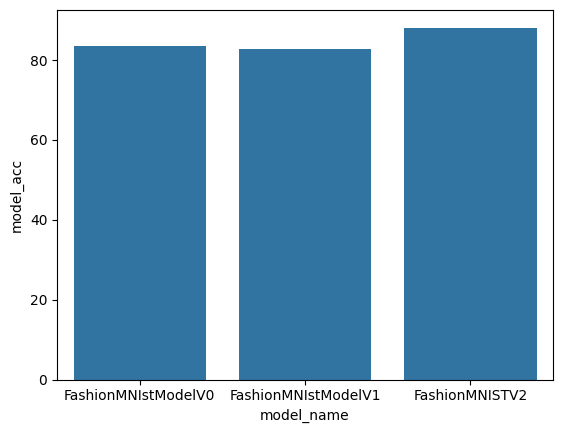

In [75]:
import seaborn as sns
sns.barplot(data=compare_results,x='model_name',y='model_acc')

In [76]:
#Make some predictions on random samples on the test dataset

In [77]:
def make_predictions(model:torch.nn.Module,data:list,device:torch.device=device):
  pred_prob=[]
  model.to(device)
  model.eval()
  with torch.inference_mode():
    for sample in data:
      sample=torch.unsqueeze(sample,dim=1).to(device)
      y_logits=model(sample)
      y_pred=torch.softmax(y_logits,dim=1)
      pred_prob.append(y_pred)
  return torch.stack(pred_prob)

In [78]:
import random
random_seed=33
test_samples=[]
test_labels=[]
for sample,label in random.sample(list(test_data),k=10):
  test_samples.append(sample)
  test_labels.append(label)
test_samples[0].shape

torch.Size([1, 28, 28])

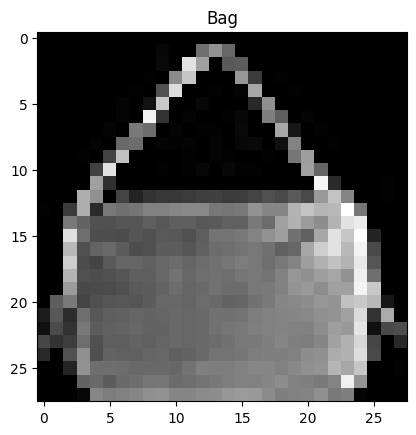

In [79]:
plt.imshow(test_samples[0].squeeze(),cmap='grey')
plt.title(class_names[test_labels[0]])
plt.show()

In [80]:
#Make Predictions

In [81]:
pred_prob=make_predictions(model=model_2,data=test_samples)

In [82]:
pred_prob

tensor([[[1.7321e-05, 2.5500e-07, 5.7203e-05, 3.9644e-05, 7.6656e-05,
          6.0845e-07, 1.8001e-05, 1.0464e-06, 9.9979e-01, 4.9045e-07]],

        [[1.2701e-03, 2.5557e-06, 6.5182e-02, 3.3586e-05, 6.8004e-01,
          5.5143e-07, 2.5340e-01, 1.7495e-07, 6.3396e-05, 2.0774e-06]],

        [[9.6992e-06, 4.1611e-05, 1.7430e-04, 2.3542e-03, 1.1005e-04,
          4.8351e-03, 4.9367e-05, 4.8603e-05, 9.9235e-01, 3.1071e-05]],

        [[4.6092e-03, 8.3082e-03, 3.6530e-04, 9.8526e-01, 3.0268e-04,
          7.7511e-06, 1.0566e-03, 1.8783e-05, 4.0745e-05, 2.6258e-05]],

        [[4.3038e-03, 1.1403e-04, 4.9173e-01, 1.1808e-04, 3.1001e-01,
          1.0269e-05, 1.9359e-01, 7.7620e-06, 9.5400e-05, 2.3936e-05]],

        [[9.8415e-01, 5.2357e-04, 4.2860e-04, 2.1501e-03, 3.9896e-05,
          5.5090e-07, 1.2658e-02, 2.3000e-07, 4.5248e-05, 1.3911e-07]],

        [[9.3377e-01, 3.7055e-06, 1.3736e-03, 4.6344e-02, 2.2743e-05,
          1.2511e-07, 1.8456e-02, 1.5104e-06, 2.6730e-05, 9.8949e-08]],


In [83]:
#Covert Pred Prob to labes
pred_classes=torch.argmax(pred_prob.squeeze(),dim=1)
pred_classes

tensor([8, 4, 8, 3, 2, 0, 0, 7, 3, 3], device='cuda:0')

In [84]:
test_labels

[8, 2, 8, 3, 2, 0, 0, 7, 3, 3]

In [85]:
#Plotting our best model predictions on test set and evaluate them

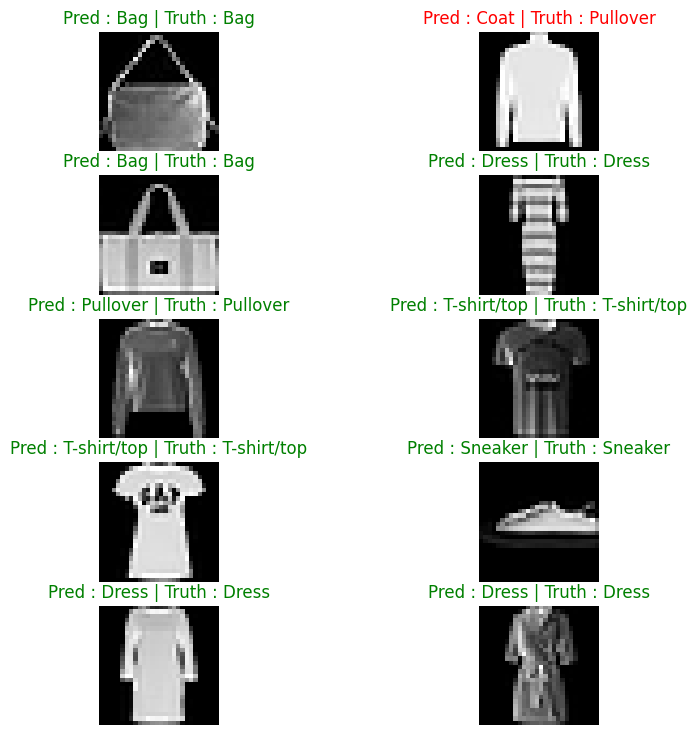

In [86]:
plt.figure(figsize=(9,9))
nrows=5
ncol=2
for i ,sample in enumerate(test_samples):
  plt.subplot(nrows,ncol,i+1)
  plt.imshow(sample.squeeze(),cmap='grey')
  if pred_classes[i]==test_labels[i]:
    color='green'
  else:
    color='red'
  plt.title(f"Pred : {class_names[pred_classes[i]]} | Truth : {class_names[test_labels[i]]}",c=color)
  plt.axis(False)

plt.show()

In [87]:
#Confusion Mateix

In [88]:
#Mke Predictions

In [89]:
from tqdm.auto import tqdm
y_preds=[]
model_2.eval()
with torch.inference_mode():
  for x,y in tqdm(test_dataloader,desc="Making Predictions"):
    x,y=x.to(device),y.to(device)
    y_logits=model_2(x)
    y_pred=y_logits.softmax(dim=1).argmax(dim=1)
    y_preds.append(y_pred.cpu())
#print(y_preds)
y_pred_tensor=torch.cat(y_preds)


Making Predictions:   0%|          | 0/313 [00:00<?, ?it/s]

In [90]:
y_pred_tensor

tensor([9, 2, 1,  ..., 8, 1, 5])

In [91]:
import mlxtend

In [92]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 24.8 MB/s eta 0:00:00


In [93]:
y_pred_tensor

tensor([9, 2, 1,  ..., 8, 1, 5])

In [94]:
import torchmetrics

In [95]:
print(mlxtend.__version__)

0.23.4


In [96]:
from torchmetrics import ConfusionMatrix

In [97]:
from mlxtend.plotting import plot_confusion_matrix

In [98]:
cm=ConfusionMatrix(num_classes=len(class_names),task='MULTICLASS')
cm_tensor=cm(preds=y_pred_tensor,target=test_data.targets)

In [99]:
cm_tensor

tensor([[848,   0,  14,  46,   3,   2,  82,   0,   5,   0],
        [  3, 958,   0,  29,   5,   0,   4,   0,   1,   0],
        [ 16,   1, 771,   8, 114,   0,  89,   0,   1,   0],
        [ 15,   5,   9, 915,  31,   0,  25,   0,   0,   0],
        [  1,   1,  52,  35, 799,   0, 112,   0,   0,   0],
        [  0,   0,   0,   0,   0, 978,   0,  16,   0,   6],
        [163,   0,  54,  41,  62,   0, 670,   0,  10,   0],
        [  0,   0,   0,   0,   0,  18,   0, 958,   0,  24],
        [  4,   0,   6,   6,   3,   4,  11,   6, 960,   0],
        [  0,   0,   0,   0,   0,   9,   0,  35,   1, 955]])

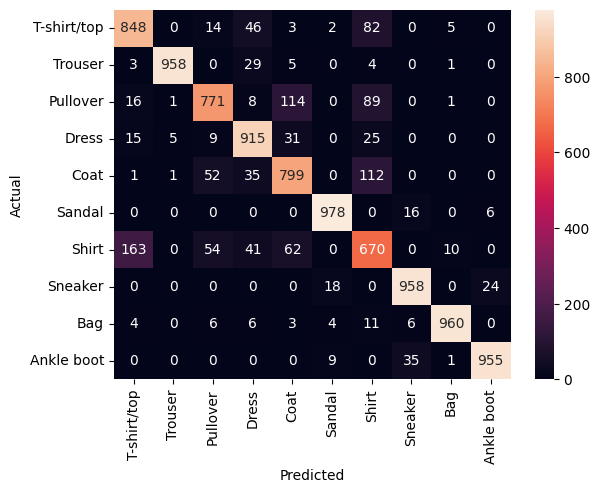

In [100]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(
    cm_tensor,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [101]:
#Saving and loading our best performance model

In [102]:
from pathlib import Path
Model_Path=Path("models")
Model_Path.mkdir(parents=True,exist_ok=True)
Model_Name="01.CnnTrainedModel.pth"
Model_Save_Path=Model_Path/Model_Name
print(f"Model saving in {Model_Save_Path}")
torch.save(obj=model_2.state_dict(),f=Model_Save_Path)

Model saving in models/01.CnnTrainedModel.pth
